# Разведочный анализ данных проекта CatchTheTour

Первичный анализ сгенерированного датасета туров (`tours_data.csv`): изучение структуры данных, расчёт основных статистик и визуализация зависимости цен от направления, звёздности отеля и сезона.


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("tours_data.csv")

display(df.head(5))
df.info()


,country,duration_days,hotel_stars,meal_type,total_price,season,user_rating
0,Осетия,3,4,Только завтраки,22900,Осень,4.5
1,Абхазия (из Уфы),7,3,Без питания,17900,Лето,4.1
2,Вьетнам,9,4,Только завтраки,38900,Зима,4.6
3,Италия,7,5,Завтраки + Обеды + Ужины,132900,Лето,4.8
4,Турция,9,4,Завтраки + Обеды + Ужины,84900,Лето,4.3


<class 'pandas.DataFrame'>
RangeIndex: 187 entries, 0 to 186
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   country        187 non-null    str    
 1   duration_days  187 non-null    int64  
 2   hotel_stars    187 non-null    int64  
 3   meal_type      187 non-null    str    
 4   total_price    187 non-null    int64  
 5   season         187 non-null    str    
 6   user_rating    187 non-null    float64
dtypes: float64(1), int64(3), str(3)
memory usage: 10.4 KB


In [9]:
# 1. Общая статистика по числовым столбцам
display(df.describe())

# 2. Средняя цена и средний рейтинг по направлениям
country_stats = df.groupby("country", as_index=False).agg(
    tours_count=("total_price", "count"),
    mean_price=("total_price", "mean"),
    mean_rating=("user_rating", "mean"),
)
country_stats = country_stats.sort_values(by="mean_price")
display(country_stats)


,duration_days,hotel_stars,total_price,user_rating
count,187.000000,187.000000,187.000000,187.000000
mean,7.449198,4.085561,67058.288770,4.418717
std,2.698334,0.705703,45718.780091,0.304664
min,3.000000,3.000000,15900.000000,3.800000
25%,6.000000,4.000000,23900.000000,4.200000
50%,7.000000,4.000000,46900.000000,4.400000
75%,9.000000,5.000000,103900.000000,4.700000
max,14.000000,5.000000,184900.000000,5.000000


,country,tours_count,mean_price,mean_rating
0,Абхазия (из Уфы),32,20528.125000,4.171875
4,Осетия,32,22884.375000,4.543750
1,Вьетнам,31,40319.354839,4.390323
5,Турция,32,90806.250000,4.387500
3,ОАЭ,29,100658.620690,4.489655
2,Италия,31,131480.645161,4.538710


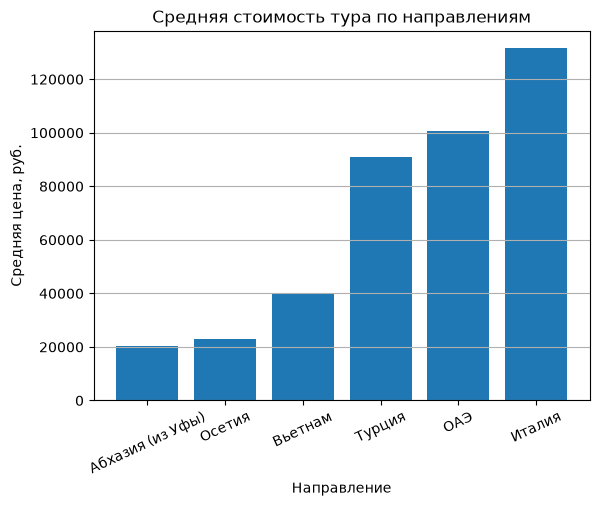

In [10]:
plt.bar(country_stats["country"], country_stats["mean_price"])

plt.title("Средняя стоимость тура по направлениям")
plt.xlabel("Направление")
plt.ylabel("Средняя цена, руб.")
plt.xticks(rotation=25)
plt.grid(axis="y")

plt.show()


,hotel_stars,mean_price,mean_rating
0,3,37735.897436,4.015385
1,4,60045.161290,4.396774
2,5,99709.090909,4.741818


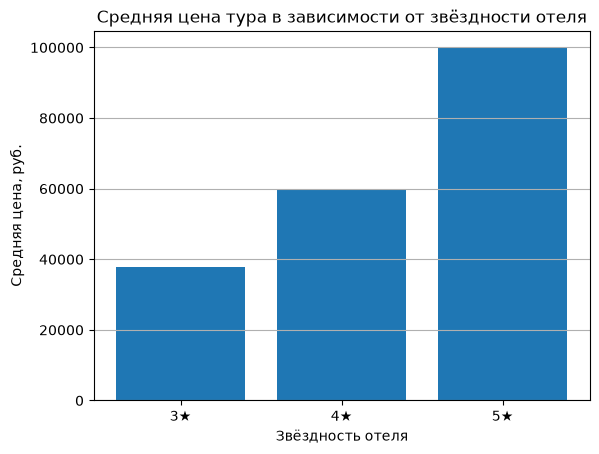

,season,total_price
0,Весна,58102.380952
3,Осень,62944.444444
1,Зима,66530.952381
2,Лето,77117.241379


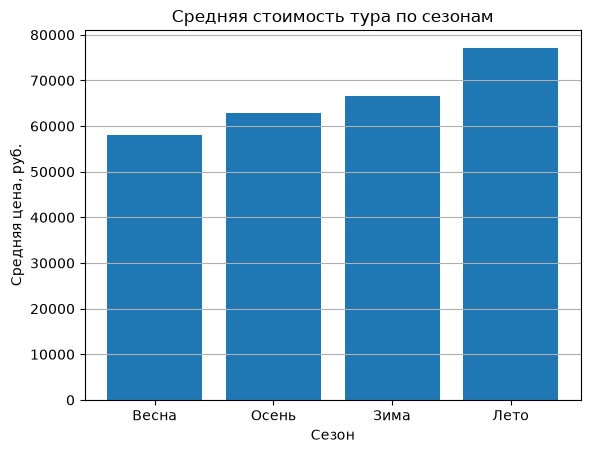

In [11]:
# 1. Зависимость цены и рейтинга от звёздности отеля
stars_stats = df.groupby("hotel_stars", as_index=False).agg(
    mean_price=("total_price", "mean"),
    mean_rating=("user_rating", "mean"),
)
display(stars_stats)

plt.bar(stars_stats["hotel_stars"].astype(str) + "★", stars_stats["mean_price"])
plt.title("Средняя цена тура в зависимости от звёздности отеля")
plt.xlabel("Звёздность отеля")
plt.ylabel("Средняя цена, руб.")
plt.grid(axis="y")
plt.show()

# 2. Зависимость средней цены от сезона
season_stats = df.groupby("season", as_index=False)["total_price"].mean()
season_stats = season_stats.sort_values(by="total_price")
display(season_stats)

plt.bar(season_stats["season"], season_stats["total_price"])
plt.title("Средняя стоимость тура по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Средняя цена, руб.")
plt.grid(axis="y")
plt.show()


## Основные выводы по анализу данных CatchTheTour

1. **Направления и бюджет:** Самыми доступными направлениями являются **Абхазия (из Уфы)** (в среднем ~20 500 руб.) и **Осетия** (~22 900 руб.), при этом Осетия лидирует по средней оценке туристов (`4.54`). Самые дорогие туры представлены в **Италию** (~131 500 руб.) и **ОАЭ** (~100 700 руб.).
2. **Звёздность отелей:** При переходе от 3★ к 5★ средняя цена тура вырастает почти в 2.6 раза (с 37 700 до 99 700 руб.), а средний рейтинг пользователей увеличивается с `4.02` до `4.74`.
3. **Сезонность:** Наиболее выгодное время для покупки путёвок — **весна** (средний чек ~58 100 руб.) и **осень** (~62 900 руб.). Пик цен приходится на **лето** (~77 100 руб.).
